Exploring a graph.

In [1]:
import requests, readline, sys, json
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn
from graph_summary import *

vertexQ is a query to get all vertex labels:

In [2]:
vertexQ

'g.V().label().groupCount()'

getQuery gets the query results, and printResp prints a response

In [3]:
printResp(getQuery(vertexQ))


{'UnnamedPipeObject': '2', 'MemoryObject': '197', 'Event': '11526', 'FileObject': '63', 'SrcSinkObject': '92', 'Principal': '2', 'Subject': '35'}


getGroupCountQuery runs a query and converts the resulting dictionary to a groupCount

In [4]:
getGroupCountQuery(vertexQ)

{'Event': 11526,
 'FileObject': 63,
 'MemoryObject': 197,
 'Principal': 2,
 'SrcSinkObject': 92,
 'Subject': 35,
 'UnnamedPipeObject': 2}

getVertices collects the counts and number of incoming and outgoing edge labels for each vertex label.  For example:

In [5]:
vertices = getVertices()
print (vertices)

Vertex types/counts:
{'UnnamedPipeObject': {'count': 2, 'in': {'predicateObject': 10}, 'out': {}}, 'MemoryObject': {'count': 197, 'in': {'predicateObject2': 101, 'predicateObject': 127}, 'out': {}}, 'Event': {'count': 11526, 'in': {}, 'out': {'predicateObject2': 101, 'subject': 11526, 'predicateObject': 11526}}, 'FileObject': {'count': 63, 'in': {'predicateObject': 389}, 'out': {}}, 'SrcSinkObject': {'count': 92, 'in': {'predicateObject': 10988}, 'out': {}}, 'Principal': {'count': 2, 'in': {'localPrincipal': 35}, 'out': {}}, 'Subject': {'count': 35, 'in': {'parentSubject': 13, 'subject': 11526, 'predicateObject': 12}, 'out': {'localPrincipal': 35, 'parentSubject': 13}}}


Likewise, getEdges collects the counts of edge labels and the number of vertex labels on the source and target of each edge.

In [6]:
edges = getEdges()
print (edges)

Edge types/counts:
{'predicateObject2': {'count': 101, 'in': {'MemoryObject': 101}, 'out': {'Event': 101}}, 'localPrincipal': {'count': 35, 'in': {'Principal': 35}, 'out': {'Subject': 35}}, 'parentSubject': {'count': 13, 'in': {'Subject': 13}, 'out': {'Subject': 13}}, 'subject': {'count': 11526, 'in': {'Subject': 11526}, 'out': {'Event': 11526}}, 'predicateObject': {'count': 11526, 'in': {'UnnamedPipeObject': 10, 'MemoryObject': 127, 'FileObject': 389, 'SrcSinkObject': 10988, 'Subject': 12}, 'out': {'Event': 11526}}}


Hmm.  Not very readable.  Let's try to do better.  printSummary takes a dictionary in one of the above forms and prints out the results in a more structured way.

In [7]:
printSummary(vertices)

{predicateObject[10]}
 -> 
UnnamedPipeObject[2]
 -> 
{}

{predicateObject2[101],
predicateObject[127]}
 -> 
MemoryObject[197]
 -> 
{}

{}
 -> 
Event[11526]
 -> 
{predicateObject2[101],
subject[11526],
predicateObject[11526]}

{predicateObject[389]}
 -> 
FileObject[63]
 -> 
{}

{predicateObject[10988]}
 -> 
SrcSinkObject[92]
 -> 
{}

{localPrincipal[35]}
 -> 
Principal[2]
 -> 
{}

{parentSubject[13],
subject[11526],
predicateObject[12]}
 -> 
Subject[35]
 -> 
{localPrincipal[35],
parentSubject[13]}



How about for edges?

In [8]:
printSummary(edges)

{MemoryObject[101]}
 -> 
predicateObject2[101]
 -> 
{Event[101]}

{Principal[35]}
 -> 
localPrincipal[35]
 -> 
{Subject[35]}

{Subject[13]}
 -> 
parentSubject[13]
 -> 
{Subject[13]}

{Subject[11526]}
 -> 
subject[11526]
 -> 
{Event[11526]}

{UnnamedPipeObject[10],
MemoryObject[127],
FileObject[389],
SrcSinkObject[10988],
Subject[12]}
 -> 
predicateObject[11526]
 -> 
{Event[11526]}



Now let's build and visualize a (bipartite) graph.  Nodes will represent either node or edge labels, and edges represent that a node can have an in-edge or out-edge with a given label (or vice versa).

In [9]:
G = nx.DiGraph()


In [10]:
G.add_nodes_from(vertices,bipartite=0)
G.add_nodes_from(edges,bipartite=1)

In [11]:
for v in vertices.keys():
    for e in vertices[v]['in'].keys():
        G.add_edge(e,v)
    for e in vertices[v]['out'].keys():
        G.add_edge(v,e)

In [12]:
nx.is_bipartite(G)

True

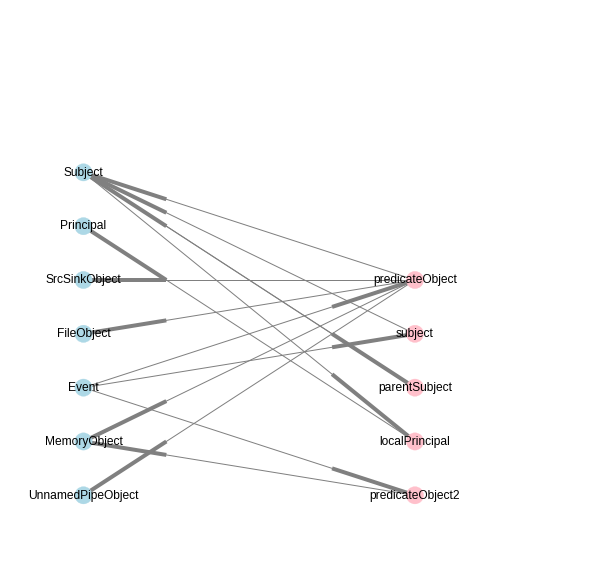

In [14]:
colors = ['lightblue' for x in vertices.keys()] + ['pink' for x in edges.keys()]
positions = {}
i = 1
for x in vertices.keys():
    positions[x] = (1,i)
    i = i + 1
i = 1
for x in edges.keys():
    positions[x] = (7,i)
    i = i + 1
fig = plt.figure(figsize=(10,10))
plt.gca().set_axis_off()   
plt.gca().set_xlim([-0.05, 10.05])    # add a little space around the plot
plt.gca().set_ylim([-0.05, 10.05])

nx.draw_networkx(G,pos=positions,
               with_labels=True,node_color=colors,edge_color='gray')

_ = plt.show()

In [90]:
all_cmdlinesQ = "g.V().has('eventType','EVENT_EXECUTE').out().values('cmdLine').as('cmd').select('cmd')"

getQuery(all_cmdlinesQ)

['./sampleload libsamplelib.so',
 '/bin/bash ./auditlog.sh',
 '/bin/bash ./auditlog.sh',
 'sudo killall -9 auditd']

In [91]:
all_filesQ = "g.V().hasLabel('FileObject').values('path').order()"

getQuery(all_filesQ)

['/bin/bash',
 '/dev/shm/testload',
 '/dev/tty',
 '/etc/default/nss',
 '/etc/fstab',
 '/etc/group',
 '/etc/ld.so.cache',
 '/etc/localtime',
 '/etc/nsswitch.conf',
 '/etc/pam.d/common-account',
 '/etc/pam.d/common-auth',
 '/etc/pam.d/common-password',
 '/etc/pam.d/common-session',
 '/etc/pam.d/common-session-noninteractive',
 '/etc/pam.d/other',
 '/etc/pam.d/sudo',
 '/etc/passwd',
 '/home/ta1/TA5/samplelib/libsamplelib.so',
 '/home/ta1/TA5/samplelib/sampleload',
 '/home/ta1/beep/scripts/auditlog.sh',
 '/lib/x86_64-linux-gnu/libc.so.6',
 '/lib/x86_64-linux-gnu/libcap.so.2',
 '/lib/x86_64-linux-gnu/libcgmanager.so.0',
 '/lib/x86_64-linux-gnu/libcrypt.so.1',
 '/lib/x86_64-linux-gnu/libdbus-1.so.3',
 '/lib/x86_64-linux-gnu/libdl.so.2',
 '/lib/x86_64-linux-gnu/libnih-dbus.so.1',
 '/lib/x86_64-linux-gnu/libnih.so.1',
 '/lib/x86_64-linux-gnu/libnsl.so.1',
 '/lib/x86_64-linux-gnu/libnss_compat.so.2',
 '/lib/x86_64-linux-gnu/libnss_files.so.2',
 '/lib/x86_64-linux-gnu/libnss_nis.so.2',
 '/lib/x8

In [96]:
all_principalsQ = "g.V().hasLabel('Principal').as('x').values('euid').as('euid').select('x').in().values('name').as('name').select('euid','name')"
getQuery(all_principalsQ)

[{'euid': '1000', 'name': 'ibus-daemon'},
 {'euid': '1000', 'name': 'window-stack-br'},
 {'euid': '1000', 'name': 'auditlog.sh'},
 {'euid': '1000', 'name': 'dbus-daemon'},
 {'euid': '1000', 'name': 'bash'},
 {'euid': '1000', 'name': 'bash'},
 {'euid': '1000', 'name': 'sampleload'},
 {'euid': '1000', 'name': 'gdbus'},
 {'euid': '1000', 'name': 'bamfdaemon'},
 {'euid': '1000', 'name': 'dbus-daemon'},
 {'euid': '1000', 'name': 'gdbus'},
 {'euid': '1000', 'name': 'hud-service'},
 {'euid': '1000', 'name': 'ibus-engine-sim'},
 {'euid': '1000', 'name': 'sampleload'},
 {'euid': '1000', 'name': 'audit.sh'},
 {'euid': '1000', 'name': 'nautilus'},
 {'euid': '1000', 'name': 'bash'},
 {'euid': '1000', 'name': 'gdbus'},
 {'euid': '1000', 'name': 'ibus-ui-gtk3'},
 {'euid': '1000', 'name': 'indicator-keybo'},
 {'euid': '1000', 'name': 'sampleload'},
 {'euid': '1000', 'name': 'gdbus'},
 {'euid': '1000', 'name': 'upstart-dbus-br'},
 {'euid': '1000', 'name': 'gnome-terminal'},
 {'euid': '1000', 'name': '

This query finds all of the network flows.

In [97]:
all_netflowQ = "g.V().hasLabel('NetFlowObject').valueMap()"
getQuery(all_netflowQ)

[]

This query finds all of the network flows of each process id.

In [29]:
proc_netflowQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').both().hasLabel('Event').both().hasLabel('NetFlowObject').valueMap()"
getQuery(proc_netflowQ)

[]

This query finds the parents of each process.

In [43]:
proc_childQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('parent').select('x').in('parentSubject').as('y').values('cid').as('child').select('parent','child')"
getQuery(proc_childQ)

[{'child': '2734', 'parent': '2328'},
 {'child': '2734', 'parent': '2328'},
 {'child': '2694', 'parent': '2321'},
 {'child': '1978', 'parent': '1904'},
 {'child': '1995', 'parent': '1904'},
 {'child': '1994', 'parent': '1904'},
 {'child': '1962', 'parent': '1904'},
 {'child': '2731', 'parent': '2694'},
 {'child': '2731', 'parent': '2694'},
 {'child': '2732', 'parent': '2731'},
 {'child': '2733', 'parent': '2731'},
 {'child': '2735', 'parent': '2734'},
 {'child': '2735', 'parent': '2734'}]

This query shows the child processes names per parent.

In [42]:
proc_child_nameQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('parent').select('x').in('parentSubject').as('y').values('name').as('child').select('parent','child')"
getQuery(proc_child_nameQ)

[{'child': 'auditlog.sh', 'parent': '2328'},
 {'child': 'bash', 'parent': '2328'},
 {'child': 'bash', 'parent': '2321'},
 {'child': 'gdbus', 'parent': '1904'},
 {'child': 'gdbus', 'parent': '1904'},
 {'child': 'ibus-engine-sim', 'parent': '1904'},
 {'child': 'ibus-ui-gtk3', 'parent': '1904'},
 {'child': 'bash', 'parent': '2694'},
 {'child': 'sampleload', 'parent': '2694'},
 {'child': 'sampleload', 'parent': '2731'},
 {'child': 'sampleload', 'parent': '2731'},
 {'child': 'auditlog.sh', 'parent': '2734'},
 {'child': 'sudo', 'parent': '2734'}]

This query shows the child process command lines per parent.

In [45]:
proc_child_nameQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('parent').select('x').in('parentSubject').as('y').values('cmdLine').as('child').select('parent','child')"
getQuery(proc_child_nameQ)

[{'child': '/bin/bash ./auditlog.sh', 'parent': '2328'},
 {'child': './sampleload libsamplelib.so', 'parent': '2694'},
 {'child': './sampleload libsamplelib.so', 'parent': '2731'},
 {'child': './sampleload libsamplelib.so', 'parent': '2731'},
 {'child': '/bin/bash ./auditlog.sh', 'parent': '2734'},
 {'child': 'sudo killall -9 auditd', 'parent': '2734'}]

This query shows files accessed per process.

In [68]:
proc_fileQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').in().hasLabel('Event').out().hasLabel('FileObject').as('z').values('path').as('file').select('pid','file').dedup()"
getQuery(proc_fileQ)

[{'file': '/usr/share/themes/Ambiance/gtk-3.0/assets/check-menuitem.png',
  'pid': '2321'},
 {'file': '/dev/shm/testload', 'pid': '2731'},
 {'file': '/lib/x86_64-linux-gnu/libdl.so.2', 'pid': '2731'},
 {'file': '/lib/x86_64-linux-gnu/libc.so.6', 'pid': '2731'},
 {'file': '/etc/ld.so.cache', 'pid': '2731'},
 {'file': '/lib/x86_64-linux-gnu/libpthread.so.0', 'pid': '2731'},
 {'file': '/lib/x86_64-linux-gnu/librt.so.1', 'pid': '2731'},
 {'file': '/home/ta1/TA5/samplelib/sampleload', 'pid': '2731'},
 {'file': '/lib64/ld-linux-x86-64.so.2', 'pid': '2731'},
 {'file': '/home/ta1/TA5/samplelib/libsamplelib.so', 'pid': '2731'},
 {'file': '/lib/x86_64-linux-gnu/libtinfo.so.5', 'pid': '2734'},
 {'file': '/lib/x86_64-linux-gnu/libc.so.6', 'pid': '2734'},
 {'file': '/dev/tty', 'pid': '2734'},
 {'file': '/proc/meminfo', 'pid': '2734'},
 {'file': '/lib/x86_64-linux-gnu/libdl.so.2', 'pid': '2734'},
 {'file': '/home/ta1/beep/scripts/auditlog.sh', 'pid': '2734'},
 {'file': '/usr/lib/x86_64-linux-gnu/gco

In [67]:
proc_event_fileQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').in().hasLabel('Event').as('y').values('eventType').as('type').select('y').out().hasLabel('FileObject').as('z').values('path').as('file').select('pid','file','type').dedup()"
getQuery(proc_event_fileQ)

[{'file': '/usr/share/themes/Ambiance/gtk-3.0/assets/check-menuitem.png',
  'pid': '2321',
  'type': 'EVENT_OPEN'},
 {'file': '/usr/share/themes/Ambiance/gtk-3.0/assets/check-menuitem.png',
  'pid': '2321',
  'type': 'EVENT_READ'},
 {'file': '/usr/share/themes/Ambiance/gtk-3.0/assets/check-menuitem.png',
  'pid': '2321',
  'type': 'EVENT_CLOSE'},
 {'file': '/dev/shm/testload', 'pid': '2731', 'type': 'EVENT_MMAP'},
 {'file': '/lib/x86_64-linux-gnu/libdl.so.2',
  'pid': '2731',
  'type': 'EVENT_READ'},
 {'file': '/dev/shm/testload', 'pid': '2731', 'type': 'EVENT_CLOSE'},
 {'file': '/lib/x86_64-linux-gnu/libc.so.6',
  'pid': '2731',
  'type': 'EVENT_MMAP'},
 {'file': '/etc/ld.so.cache', 'pid': '2731', 'type': 'EVENT_MMAP'},
 {'file': '/lib/x86_64-linux-gnu/libpthread.so.0',
  'pid': '2731',
  'type': 'EVENT_CLOSE'},
 {'file': '/lib/x86_64-linux-gnu/librt.so.1',
  'pid': '2731',
  'type': 'EVENT_OPEN'},
 {'file': '/etc/ld.so.cache', 'pid': '2731', 'type': 'EVENT_CLOSE'},
 {'file': '/dev/sh

In [71]:
proc_eventQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').in().hasLabel('Event').as('y').values('eventType').as('type').select('pid','type').dedup()"
getQuery(proc_eventQ)

[{'pid': '2710', 'type': 'EVENT_READ'},
 {'pid': '2710', 'type': 'EVENT_WRITE'},
 {'pid': '2710', 'type': 'EVENT_EXIT'},
 {'pid': '2328', 'type': 'EVENT_READ'},
 {'pid': '2328', 'type': 'EVENT_CLOSE'},
 {'pid': '2328', 'type': 'EVENT_WRITE'},
 {'pid': '2328', 'type': 'EVENT_FORK'},
 {'pid': '2321', 'type': 'EVENT_WRITE'},
 {'pid': '2321', 'type': 'EVENT_RECVMSG'},
 {'pid': '2321', 'type': 'EVENT_READ'},
 {'pid': '2321', 'type': 'EVENT_OPEN'},
 {'pid': '2321', 'type': 'EVENT_CLOSE'},
 {'pid': '2122', 'type': 'EVENT_WRITE'},
 {'pid': '2122', 'type': 'EVENT_RECVMSG'},
 {'pid': '2122', 'type': 'EVENT_READ'},
 {'pid': '1980', 'type': 'EVENT_RECVMSG'},
 {'pid': '1980', 'type': 'EVENT_WRITE'},
 {'pid': '1980', 'type': 'EVENT_READ'},
 {'pid': '2323', 'type': 'EVENT_WRITE'},
 {'pid': '2323', 'type': 'EVENT_RECVMSG'},
 {'pid': '2323', 'type': 'EVENT_READ'},
 {'pid': '2323', 'type': 'EVENT_SENDMSG'},
 {'pid': '1958', 'type': 'EVENT_WRITE'},
 {'pid': '1958', 'type': 'EVENT_RECVMSG'},
 {'pid': '195

In [79]:
proc_execQ = "g.V().hasLabel('Subject').has('subjectType','SUBJECT_PROCESS').as('x').values('cid').as('pid').select('x').both().has('eventType','EVENT_EXECUTE').out().values('cmdLine').as('cmd').select('pid','cmd')"
getQuery(proc_execQ)

[{'cmd': './sampleload libsamplelib.so', 'pid': '2731'},
 {'cmd': './sampleload libsamplelib.so', 'pid': '2731'},
 {'cmd': '/bin/bash ./auditlog.sh', 'pid': '2734'},
 {'cmd': '/bin/bash ./auditlog.sh', 'pid': '2734'},
 {'cmd': '/bin/bash ./auditlog.sh', 'pid': '2735'},
 {'cmd': 'sudo killall -9 auditd', 'pid': '2735'},
 {'cmd': '/bin/bash ./auditlog.sh', 'pid': '2735'},
 {'cmd': 'sudo killall -9 auditd', 'pid': '2735'}]

In [81]:
labels_edgesQ = "g.V().as('x').label().as('v').select('x').outE().label().as('l').select('x').out().label().as('w').select('v','l','w').dedup()"
getQuery(labels_edgesQ)

[{'l': 'subject', 'v': 'Event', 'w': 'Subject'},
 {'l': 'subject', 'v': 'Event', 'w': 'SrcSinkObject'},
 {'l': 'predicateObject', 'v': 'Event', 'w': 'Subject'},
 {'l': 'predicateObject', 'v': 'Event', 'w': 'SrcSinkObject'},
 {'l': 'localPrincipal', 'v': 'Subject', 'w': 'Principal'},
 {'l': 'localPrincipal', 'v': 'Subject', 'w': 'Subject'},
 {'l': 'parentSubject', 'v': 'Subject', 'w': 'Principal'},
 {'l': 'parentSubject', 'v': 'Subject', 'w': 'Subject'},
 {'l': 'subject', 'v': 'Event', 'w': 'UnnamedPipeObject'},
 {'l': 'predicateObject', 'v': 'Event', 'w': 'UnnamedPipeObject'},
 {'l': 'subject', 'v': 'Event', 'w': 'FileObject'},
 {'l': 'predicateObject', 'v': 'Event', 'w': 'FileObject'},
 {'l': 'subject', 'v': 'Event', 'w': 'MemoryObject'},
 {'l': 'predicateObject', 'v': 'Event', 'w': 'MemoryObject'},
 {'l': 'predicateObject2', 'v': 'Event', 'w': 'MemoryObject'},
 {'l': 'predicateObject2', 'v': 'Event', 'w': 'Subject'},
 {'l': 'predicateObject2', 'v': 'Event', 'w': 'FileObject'}]